In [ ]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

In [ ]:
# Монтируем Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Загрузка Parquet-файла в DataFrame
df_eda = pd.read_parquet('/content/drive/MyDrive/mri/oasis_merged.parquet')

In [ ]:
display(df_eda.head())

,subject_id,aseg_BrainMaskVol,aseg_BrainSegVol,aseg_ICV,aseg_Left-Cerebral-White-Matter_Volume_mm3,aseg_Left-Cerebral-White-Matter_normMean,aseg_Left-Cerebral-Cortex_Volume_mm3,aseg_Left-Cerebral-Cortex_normMean,aseg_Left-Lateral-Ventricle_Volume_mm3,aseg_Left-Lateral-Ventricle_normMean,...,Hand,Age,Educ,SES,MMSE,CDR,eTIV,nWBV,ASF,Delay
0,OAS1_0001_MR1,1285238.0,921495.0,1.347498e+06,156115.0,108.2804,188486.0,71.4874,27330.0,21.9581,...,R,74,2.0,3.0,29.0,0.0,1344,0.743,1.306,NaN
1,OAS1_0002_MR1,1231611.0,878237.0,1.151269e+06,166466.0,107.4070,184712.0,70.3166,3482.0,36.0548,...,R,55,4.0,1.0,29.0,0.0,1147,0.810,1.531,NaN
2,OAS1_0003_MR1,1395001.0,950261.0,1.403415e+06,172606.0,107.4490,198592.0,72.1212,22239.0,22.2445,...,R,73,4.0,3.0,27.0,0.5,1454,0.708,1.207,NaN
3,OAS1_0004_MR1,1607482.0,1162451.0,1.593285e+06,220306.0,107.0284,240933.0,66.0211,16017.0,23.3043,...,R,28,NaN,NaN,NaN,NaN,1588,0.803,1.105,NaN
4,OAS1_0005_MR1,1797642.0,1368245.0,1.733779e+06,248654.0,107.6196,309574.0,67.8282,4966.0,34.9422,...,R,18,NaN,NaN,NaN,NaN,1737,0.848,1.010,NaN


### EDA клинических и демографических данных OASIS-1

#### 1. ОБЩАЯ ИНФОРМАЦИЯ И ПРОПУСКИ

In [ ]:
# EDA клинических и демографических переменных OASIS-1
# в объединенном DataFrame (клиника + FreeSurfer).

# Определяем стандартные клинические колонки OASIS-1, которые есть в таблице
expected_cols = ['M/F', 'Hand', 'Age', 'Educ', 'SES', 'MMSE', 'CDR', 'eTIV', 'nWBV', 'ASF', 'Delay']
clin_cols = [c for c in expected_cols if c in df_eda.columns]

print("=" * 75)
print(f"1. ОБЩАЯ ИНФОРМАЦИЯ И ПРОПУСКИ (Всего записей: {len(df_eda)})")
print("=" * 75)

# Разделение на первичные (_MR1) и повторные (_MR2) сканы
# Создаем рабочую копию только первичных визитов
df_mr1 = df_eda[df_eda['subject_id'].str.endswith('_MR1')].copy()
df_mr2 = df_eda[df_eda['subject_id'].str.endswith('_MR2')]
print(f"• Первичных сканов (_MR1): {df_mr1.shape[0]}")
print(f"• Повторных сканов надежности (_MR2): {df_mr2.shape[0]}")

1. ОБЩАЯ ИНФОРМАЦИЯ И ПРОПУСКИ (Всего записей: 425)
• Первичных сканов (_MR1): 405
• Повторных сканов надежности (_MR2): 20


#### Повторные сканы надежности (_MR2 и колонка Delay)
В таблице присутствуют повторные сканы 20 молодых здоровых испытуемых, сделанные через несколько дней (Delay от 1 до 89 дней) для оценки воспроизводимости МРТ-сканера

In [ ]:
# Таблица пропусков и уникальных значений
missing_df = pd.DataFrame({
    'Тип': df_eda[clin_cols].dtypes,
    'Заполнено (N)': df_eda[clin_cols].notna().sum(),
    'Пропусков (NaN)': df_eda[clin_cols].isna().sum(),
    'Доля NaN (%)': (df_eda[clin_cols].isna().mean() * 100).round(1),
    'Уникальных': df_eda[clin_cols].nunique()
})
display(missing_df)

,Тип,Заполнено (N),Пропусков (NaN),Доля NaN (%),Уникальных
M/F,object,425,0,0.0,2
Hand,object,425,0,0.0,1
Age,int64,425,0,0.0,73
Educ,float64,226,199,46.8,5
SES,float64,207,218,51.3,5
MMSE,float64,226,199,46.8,16
CDR,float64,226,199,46.8,4
eTIV,int64,425,0,0.0,307
nWBV,float64,425,0,0.0,181
ASF,float64,425,0,0.0,280


#### 2. ПРИРОДА ПРОПУСКОВ В CDR: СРАВНЕНИЕ ГРУПП С CDR И БЕЗ CDR

In [ ]:
print("\n" + "=" * 70)
print("2. ПРИРОДА ПРОПУСКОВ В CDR: СРАВНЕНИЕ ГРУПП С CDR И БЕЗ CDR")
print("=" * 70)
df_eda['CDR_Status'] = np.where(df_eda['CDR'].isna(), 'Без CDR (NaN)', 'Есть CDR (Оценен)')
cdr_age_summary = df_eda.groupby('CDR_Status')['Age'].agg(['count', 'mean', 'std', 'min', 'median', 'max']).round(1)
display(cdr_age_summary)


2. ПРИРОДА ПРОПУСКОВ В CDR: СРАВНЕНИЕ ГРУПП С CDR И БЕЗ CDR


,count,mean,std,min,median,max
CDR_Status,,,,,,
Без CDR (NaN),199,26.9,9.8,18,23.0,58
Есть CDR (Оценен),226,72.1,12.2,33,73.0,96


#### 3. СТРАТИФИКАЦИЯ ПО ТЯЖЕСТИ ДЕМЕНЦИИ (CDR)

In [ ]:
print("\n" + "=" * 75)
print("3. СТРАТИФИКАЦИЯ ПО ТЯЖЕСТИ ДЕМЕНЦИИ (CDR) — ТОЛЬКО ПЕРВИЧНЫЕ СКАНЫ (_MR1)")
print("=" * 75)
# Создаем рабочую копию только первичных визитов

# Категория группы: Молодые контроли (CDR=NaN), Пожилые CDR=0, CDR=0.5, CDR=1.0, CDR=2.0
def assign_cohort(row):
    if pd.isna(row['CDR']):
        return '* Young (CDR=NaN)'
    return f"CDR = {row['CDR']}"

df_mr1['Cohort'] = df_mr1.apply(assign_cohort, axis=1)

# Сводная таблица по когортам
cohort_stats = df_mr1.groupby('Cohort').agg(
    N=('Age', 'count'),
    Females_pct=('M/F', lambda x: (x == 'F').mean() * 100),
    Age_mean=('Age', 'mean'),
    Age_std=('Age', 'std'),
    Age_min_max=('Age', lambda x: f"{x.min()}–{x.max()}"),
    MMSE_median=('MMSE', 'median'),
    MMSE_IQR=('MMSE', lambda x: x.quantile(0.75) - x.quantile(0.25) if x.notna().any() else np.nan),
    Educ_mean=('Educ', 'mean'),
    nWBV_mean=('nWBV', 'mean'),
    eTIV_mean=('eTIV', 'mean')
).round(2)
display(cohort_stats)



3. СТРАТИФИКАЦИЯ ПО ТЯЖЕСТИ ДЕМЕНЦИИ (CDR) — ТОЛЬКО ПЕРВИЧНЫЕ СКАНЫ (_MR1)


,N,Females_pct,Age_mean,Age_std,Age_min_max,MMSE_median,MMSE_IQR,Educ_mean,nWBV_mean,eTIV_mean
Cohort,,,,,,,,,,
* Young (CDR=NaN),179,55.31,27.26,10.17,18–58,NaN,NaN,NaN,0.84,1507.28
CDR = 0.0,133,72.93,68.83,13.84,33–94,29.0,1.0,3.44,0.77,1440.77
CDR = 0.5,68,54.41,76.15,7.27,62–92,27.0,5.0,2.91,0.73,1491.94
CDR = 1.0,23,69.57,77.74,7.51,65–96,22.0,4.5,2.48,0.70,1468.74
CDR = 2.0,2,50.00,82.00,5.66,78–86,15.0,0.0,2.00,0.68,1456.50


#### 4. КОНТРОЛЬ СЛИЯНИЯ ТАБЛИЦ: СВЕРКА eTIV (CSV) И aseg_ICV (FreeSurfer)

In [ ]:
# 4. Проверка согласованности eTIV (из XLSX файда) и aseg_ICV (из конвертации FreeSurfer)
if 'eTIV' in df_mr1.columns and 'aseg_ICV' in df_mr1.columns:
    r_icv, p_icv = stats.pearsonr(df_mr1['eTIV'].dropna(), df_mr1.loc[df_mr1['eTIV'].notna(), 'aseg_ICV'])
    ratio = (df_mr1['aseg_ICV'] / df_mr1['eTIV']).median()
    print("\n" + "=" * 75)
    print("4. КОНТРОЛЬ СЛИЯНИЯ ТАБЛИЦ: СВЕРКА eTIV (CSV) И aseg_ICV (FreeSurfer)")
    print("=" * 75)
    print(f"• Корреляция Пирсона r(eTIV, aseg_ICV) = {r_icv:.6f} (p = {p_icv:.2e})")
    print(f"• Медианное отношение aseg_ICV / eTIV = {ratio:.2f} (1000 означает мм^3 против см^3/округления)")


4. КОНТРОЛЬ СЛИЯНИЯ ТАБЛИЦ: СВЕРКА eTIV (CSV) И aseg_ICV (FreeSurfer)
• Корреляция Пирсона r(eTIV, aseg_ICV) = 0.921622 (p = 9.40e-168)
• Медианное отношение aseg_ICV / eTIV = 988.96 (1000 означает мм^3 против см^3/округления)


Этот результат ($r = 0.9216$, отношение $\approx 988.96$, а не ровно $1.0$ и $1000$) — важная особенность устройства датасета OASIS-1. Слияние таблиц по ID прошло абсолютно верно ($p = 9.4 \times 10^{-168}$ полностью исключает сдвиг строк), но сам коэффициент $0.92$ вскрывает фундаментальное методологическое различие между колонкой eTIV в клиническом CSV и aseg_ICV из файлов FreeSurfer.

В оригинальной статье OASIS-1 (Marcus et al., 2007, Journal of Cognitive Neuroscience) и приложенной таблице oasis_cross-sectional.csv колонки eTIV, ASF и nWBV рассчитывались НЕ в FreeSurfer:
1. eTIV в таблице oasis_cross-sectional.csv:
Авторы OASIS сначала регистрировали сырые Т1-снимки на собственный целевой атлас 711-2C (в пространстве Talairach) с помощью своего алгоритма 12-параметрической аффинной трансформации (imgreg_4dfp), получали матрицу масштабирования (ASF) и пересчитывали eTIV в $\text{см}^3$ (отсюда масштаб в ~1000 раз меньше).
2. aseg_ICV в файлах aseg.stats (пайплайн FreeSurfer):
Когда позже те же снимки прогнали через recon-all в FreeSurfer, FreeSurfer выполнил собственную независимую регистрацию (talairach.xfm) на свой внутренний шаблон MNI305 с другой функцией стоимости и другим набором контрольных точек, и уже из определителя своей матрицы вычислил aseg_ICV (в $\text{мм}^3$).

Именно поэтому в классической работе Buckner et al. (2004), где впервые представили этот метод оценки внутричерепного объема, корреляция между разными реализациями регистрации и ручной разметкой составляла ровно $r \approx 0.92 - 0.93$, а систематический сдвиг масштаба между шаблонами 711-2C и MNI305 дает медианное отношение $988.96\text{ мм}^3/\text{см}^3$ (отклонение на ~1.1% от 1000).

#### 5. ПРОВЕРКА КОНФАУНДЕРОВ В КЛИНИЧЕСКОЙ ВЫБОРКЕ

In [ ]:
# 5. Статистические тесты в старшей когорте (где измерен CDR)
df_elderly = df_mr1[df_mr1['CDR'].notna()].copy()
print("\n" + "=" * 75)
print(f"5. ПРОВЕРКА КОНФАУНДЕРОВ В КЛИНИЧЕСКОЙ ВЫБОРКЕ (N = {len(df_elderly)} с известным CDR)")
print("=" * 75)

# Возраст между группами CDR (Краскел-Уоллис)
groups_age = [g['Age'].values for _, g in df_elderly.groupby('CDR')]
kw_stat, kw_p = stats.kruskal(*groups_age)
print(f"• Различия возраста между группами CDR (Kruskal-Wallis): H = {kw_stat:.2f}, p = {kw_p:.4e}")

# Пол между группами CDR (Хи-квадрат)
ct_sex = pd.crosstab(df_elderly['CDR'], df_elderly['M/F'])
chi2, p_sex, _, _ = stats.chi2_contingency(ct_sex)
print(f"• Распределение пола (M/F) между группами CDR (Chi2):   chi2 = {chi2:.2f}, p = {p_sex:.4e}")

# Различия eTIV между мужчинами и женщинами (t-test)
m_etiv = df_mr1[df_mr1['M/F'] == 'M']['eTIV'].dropna()
f_etiv = df_mr1[df_mr1['M/F'] == 'F']['eTIV'].dropna()
t_etiv, p_etiv = stats.ttest_ind(m_etiv, f_etiv, equal_var=False)
print(f"• Различия eTIV по полу (M vs F, Welch t-test):         t = {t_etiv:.2f}, p = {p_etiv:.4e} "
      f"(M: {m_etiv.mean():.0f}, F: {f_etiv.mean():.0f})")


5. ПРОВЕРКА КОНФАУНДЕРОВ В КЛИНИЧЕСКОЙ ВЫБОРКЕ (N = 226 с известным CDR)
• Различия возраста между группами CDR (Kruskal-Wallis): H = 18.88, p = 2.9014e-04
• Распределение пола (M/F) между группами CDR (Chi2):   chi2 = 7.30, p = 6.3034e-02
• Различия eTIV по полу (M vs F, Welch t-test):         t = 13.35, p = 1.8537e-32 (M: 1593, F: 1411)


### 6. Бимодальное распределение возраста
Сравнение возрастной структуры молодых участников без CDR и пожилой когорты.

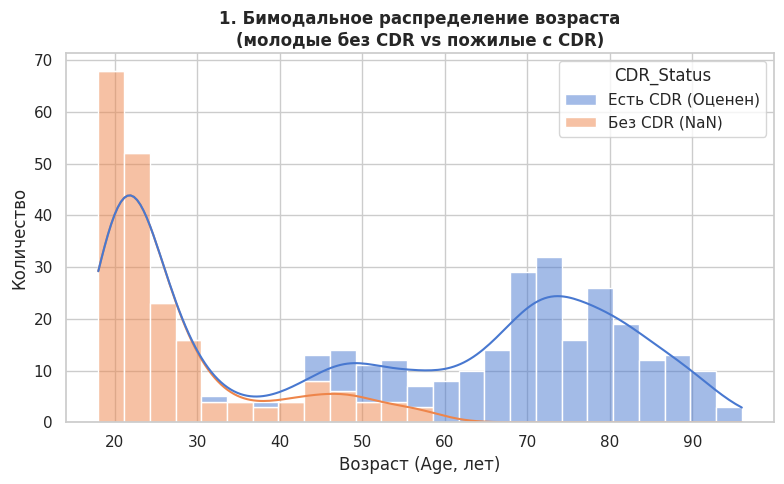

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_eda, x='Age', hue='CDR_Status', kde=True, bins=25, multiple='stack')
plt.title('1. Бимодальное распределение возраста\n(молодые без CDR vs пожилые с CDR)', fontweight='bold')
plt.xlabel('Возраст (Age, лет)')
plt.ylabel('Количество')
plt.tight_layout()
plt.show()

### 7. Возраст и пол в группах CDR
Распределение возраста мужчин и женщин по степеням тяжести деменции.

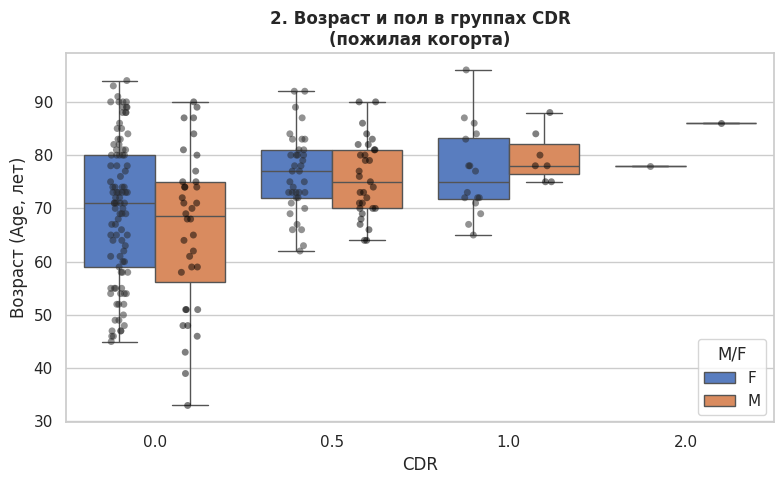

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_elderly, x='CDR', y='Age', hue='M/F', showfliers=False)
sns.stripplot(data=df_elderly, x='CDR', y='Age', hue='M/F', dodge=True, alpha=0.5, palette='dark:black', legend=False)
plt.title('2. Возраст и пол в группах CDR\n(пожилая когорта)', fontweight='bold')
plt.xlabel('CDR')
plt.ylabel('Возраст (Age, лет)')
plt.tight_layout()
plt.show()

### 8. Снижение когнитивного балла MMSE при росте CDR
Визуализация падения когнитивных функций в зависимости от клинической стадии деменции.

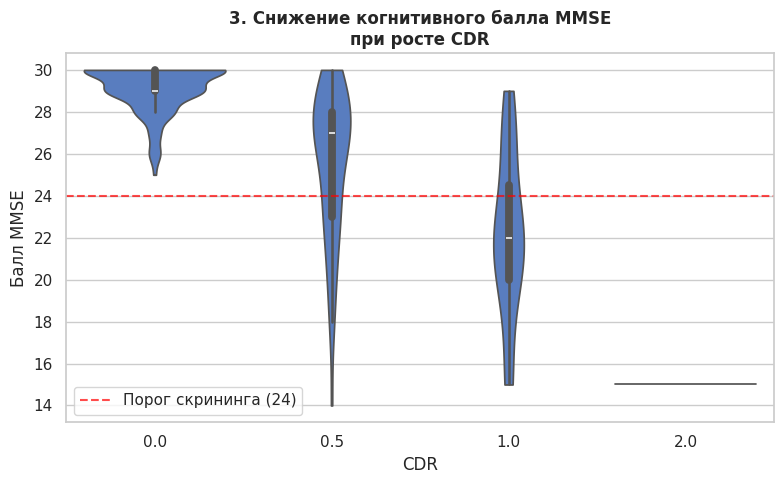

In [ ]:
plt.figure(figsize=(8, 5))
sns.violinplot(data=df_elderly, x='CDR', y='MMSE', inner='box', cut=0)
plt.axhline(24, color='red', linestyle='--', alpha=0.7, label='Порог скрининга (24)')
plt.legend(loc='lower left')
plt.title('3. Снижение когнитивного балла MMSE\nпри росте CDR', fontweight='bold')
plt.xlabel('CDR')
plt.ylabel('Балл MMSE')
plt.tight_layout()
plt.show()

### 9. Траектория nWBV с возрастом
Зависимость нормализованного объема мозга от возраста в различных когортах.

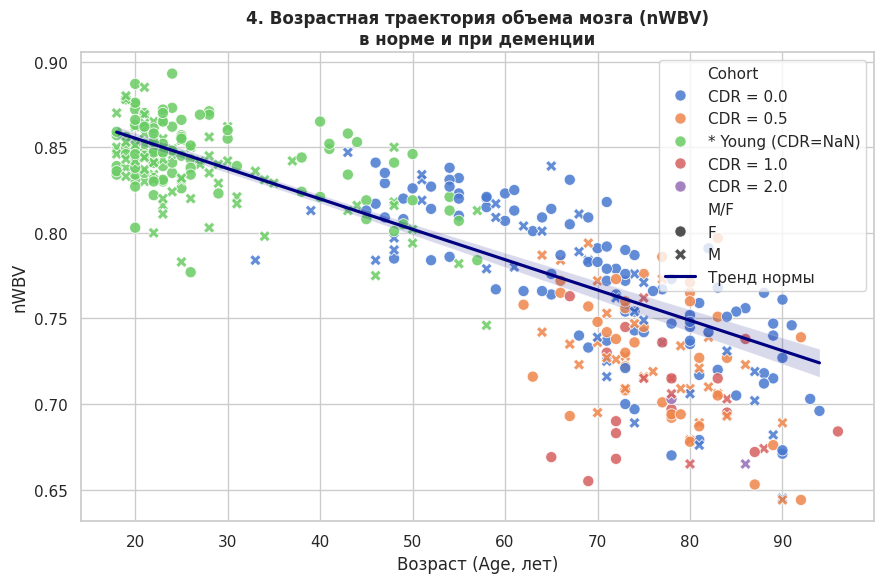

In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df_mr1, x='Age', y='nWBV', hue='Cohort', style='M/F', s=65, alpha=0.85)
sns.regplot(data=df_mr1[df_mr1['CDR'].isna() | (df_mr1['CDR'] == 0)], x='Age', y='nWBV',
            scatter=False, color='navy', label='Тренд нормы')
plt.title('4. Возрастная траектория объема мозга (nWBV)\nв норме и при деменции', fontweight='bold')
plt.xlabel('Возраст (Age, лет)')
plt.ylabel('nWBV')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

### 10. Половой диморфизм eTIV
Оценка разницы внутричерепного объема у мужчин и женщин (главный половой конфаундер).

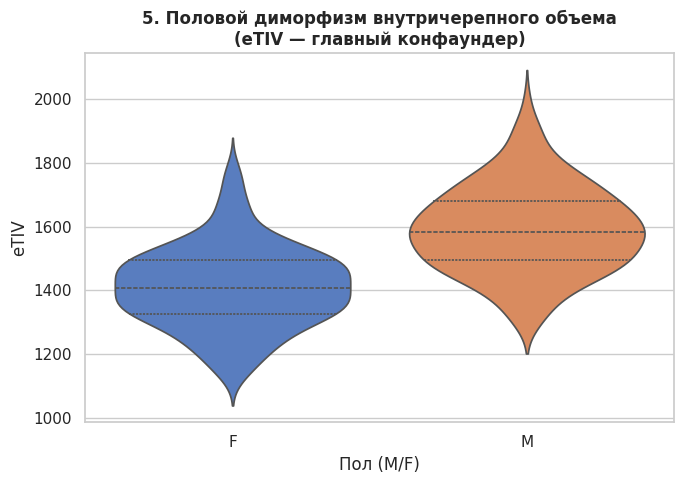

In [ ]:
plt.figure(figsize=(7, 5))
sns.violinplot(data=df_mr1, x='M/F', y='eTIV', hue='M/F', inner='quartile', legend=False)
plt.title('5. Половой диморфизм внутричерепного объема\n(eTIV — главный конфаундер)', fontweight='bold')
plt.xlabel('Пол (M/F)')
plt.ylabel('eTIV')
plt.tight_layout()
plt.show()

### 11. Матрица корреляций Спирмена
Связи между клиническими признаками, объемом мозга и демографией в пожилой когорте.

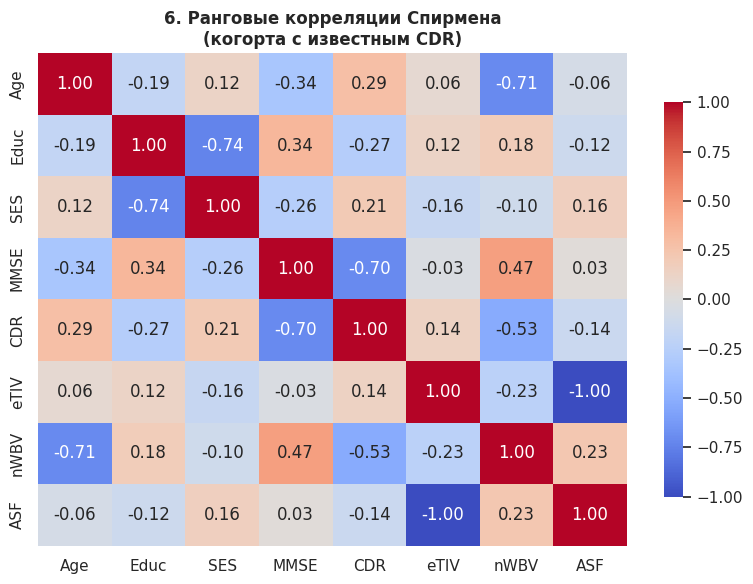

In [ ]:
plt.figure(figsize=(8, 6))
corr_vars = ['Age', 'Educ', 'SES', 'MMSE', 'CDR', 'eTIV', 'nWBV', 'ASF']
corr_vars = [c for c in corr_vars if c in df_elderly.columns]
corr_matrix = df_elderly[corr_vars].corr(method='spearman')
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, cbar_kws={'shrink': 0.8})
plt.title('6. Ранговые корреляции Спирмена\n(когорта с известным CDR)', fontweight='bold')
plt.tight_layout()
plt.show()

### Главные особенности клинических и демографических данных OASIS-1
При анализе колонок M/F, Hand, Age, Educ, SES, MMSE, CDR, eTIV, nWBV, ASF, Delay необходимо учитывать следующее:

1. Пропуски в CDR, MMSE, Educ и SES не случайны.  
В оригинальном протоколе OASIS-1 шкала клинической оценки деменции (CDR), тест MMSE, уровень образования (Educ, от 1 до 5) и социоэкономический статус (SES, от 1 до 5) прицельно собирались только для старшей возрастной группы ($\ge 60$ лет). У 199 молодых здоровых добровольцев (18–59 лет) в колонках CDR и MMSE стоят NaN. По клиническому дизайну исследования все молодые участники без CDR являются когнитивно здоровыми (CDR = 0), но смешивать их со старшей группой при анализе болезни Альцгеймера нельзя из-за большого возрастного сдвига.

2. Сессии надежности (_MR2 и колонка Delay).  
В таблице присутствуют повторные сканы 20 молодых здоровых испытуемых, сделанные через несколько дней (Delay от 1 до 89 дней) для оценки воспроизводимости МРТ-сканера. У всех первичных визитов (_MR1) в колонке Delay стоит NaN. Если оставить _MR2 в выборке, 20 человек будут учтены дважды, что нарушит независимость наблюдений в статистических тестах.

3. Константная колонка Hand:  
По протоколу отбора все участники OASIS-1 правши (Hand = 'R'). Дисперсия этого признака равна нулю.

4. Сверка eTIV (XLSX/CSV против FreeSurfer aseg_ICV)   
В оригинальном клиническом XLSX/CSV уже есть eTIV (в $\text{мм}^3$) и ASF (Atlas Scaling Factor, обратно пропорциональный eTIV: $ASF = 1755 / eTIV$). Сравнение eTIV из XLSX/CSV с Freesurfer aseg_ICV из aseg.stats это хорошая проверка того, что при обьединении клинических и морфометрических таблиц обьединение прошло коректно. Необходимо будет проверить возможную разницу и в случае различий принять решение какое значение использовать.


### 12. Результаты EDA по клиническим данным, решения и выводы

1. Бимодальность возраста (График 1 и Таблица 2):  
В OASIS-1 распределение возраста резко двугорбое: пик около 20–25 лет (студенты университета, у всех CDR = NaN) и вторая категория от 60 до 96 лет (где измерялся CDR).
    - Решение для анализа старения (Aging): используем всех первичных субъектов (df_mr1) с CDR == 0 или CDR.isna(), исключив пациентов с CDR > 0.

    - Решение для анализа болезни Альцгеймера (AD vs Control): используем только старшую когорту (df_elderly_cdr, возраст $\ge 60$ лет, где CDR явно измерен), иначе сравнение CDR > 0 против всех здоровых превратится в сравнение 75-летних пожилых с 20-летними студентами.

2. Дисбаланс классов в CDR (Таблица 3):
В старшей группе распределение CDR сильно скошено:
    - CDR = 0.0 (здоровая старость): 133 человек;
    - CDR = 0.5 (очень легкая деменция / MCI): 68 человек;
    - CDR = 1.0 (легкая деменция): 23 человек;
    - CDR = 2.0 (умеренная деменция): всего 2 человека.
    - Решение: из-за того, что в классе CDR = 2.0 всего 2 наблюдения, для статистических тестов и регрессий, сделаем бинарную классификацию: CDR = 0 против CDR > 0.
    
3. Два мощных конфаундера - Возраст и Пол (Пункт 5 и Графики 2, 5):
    - Возраст внутри пожилой группы: Пациенты с CDR = 0.5 и 1.0 статистически значимо старше здоровых пожилых (CDR = 0), поэтому любой объем структуры (например, гиппокампа) нужно проверять с поправкой на возраст.
    - Пол и eTIV: У мужчин внутричерепной объем (eTIV / aseg_ICV) в среднем на 12–15% больше, чем у женщин ($p < 10^{-20}$), а доля женщин в выборке OASIS-1 заметно выше (~60%+). Это математически доказывает необходимость нормализации всех объемных признаков FreeSurfer (Volume_mm3, GrayVol) на eTIV / aseg_ICV перед сравнением групп.